<a href="https://colab.research.google.com/github/a00842247-alt/evidencies_2039_2026/blob/main/Presentacion_(A6_Intermediate_presentations_(pre_class_activity_and_during_class).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Análisis del comportamiento financiero y hábitos de pago en clientes de tarjetas de crédito

### Tabla de Contenido

0. [Tabla de Contenido](#scrollTo=Z6M2eryOpIT7)
1. [Descripción del Dataset](#scrollTo=UgG9jfGFoIqJ)
2. [Descripción de las Variables de Interés](#scrollTo=BykyyzZyoU0C)
3. [Pregunta de Investigación 1](#scrollTo=ekYobK_cogiS)
4. [Pregunta de Investigación 2](#scrollTo=i3SJX2l-oqBF)

## 1. Descripción del Dataset

* **Fuente:** Repositorio público de análisis financiero (Kaggle), datos reales anonimizados de tarjetas de crédito.
* **Contexto:** Contiene el historial de comportamiento financiero de tarjetahabientes activos durante 6 meses (saldos, límites de crédito, compras, adelantos de efectivo y pagos).
* **Observaciones:** 8,950 filas.
* **Variables:** 18 columnas originales.
* **Unidad de observación:** Cada fila representa un cliente único (`cust_id`) y cada columna representa un indicador de su comportamiento financiero.

[Volver al inicio](#scrollTo=Z6M2eryOpIT7)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from scipy import stats

df = pd.read_csv('CreditCard.csv')
df.columns = df.columns.str.lower()
df.head(2)

,cust_id,balance,balance_frequency,purchases,oneoff_purchases,installments_purchases,cash_advance,purchases_frequency,oneoff_purchases_frequency,purchases_installments_frequency,cash_advance_frequency,cash_advance_trx,purchases_trx,credit_limit,payments,minimum_payments,prc_full_payment,tenure
0,C10001,40.900749,0.818182,95.4,0.0,95.4,0.000000,0.166667,0.0,0.083333,0.00,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.0,0.0,0.0,6442.945483,0.000000,0.0,0.000000,0.25,4,0,7000.0,4103.032597,1072.340217,0.222222,12


## 2. Descripción de las Variables de Interés

De acuerdo con las reglas de nomenclatura y su clasificación estadística, se seleccionan únicamente las variables utilizadas en el análisis:

| Variable | Descripción | Tipo de Variable | Unidad / Categorías |
| :--- | :--- | :--- | :--- |
| `cust_id` | Identificador único del cliente | Categórica Nominal | Texto (`C10001` - `C19190`) |
| `balance` | Saldo acumulado pendiente en la tarjeta | Numérica Continua | Dólares (USD) |
| `purchases` | Monto total de compras realizadas | Numérica Continua | Dólares (USD) |
| `cash_advance` | Monto total retirado en adelantos de efectivo | Numérica Continua | Dólares (USD) |
| `credit_limit` | Límite de crédito aprobado para el cliente | Numérica Continua | Dólares (USD) |
| `payments` | Monto total de pagos realizados | Numérica Continua | Dólares (USD) |
| `purchases_trx` | Número total de transacciones de compra | Numérica Discreta | Conteo de operaciones |
| `tenure` | Antigüedad del servicio de la tarjeta | Numérica Discreta / Ordinal | Meses (6 a 12) |

In [2]:
favs = ['cust_id', 'balance', 'purchases', 'cash_advance', 'credit_limit', 'payments', 'purchases_trx', 'tenure']
ndf = df[favs].copy()

overview = pd.DataFrame({
    'Data type': ndf.dtypes,
    'Missing Values': ndf.isna().sum(),
    'Unique Values': ndf.nunique(),
    'Missing %': (ndf.isna().sum() / ndf.shape[0]) * 100
})
overview

,Data type,Missing Values,Unique Values,Missing %
cust_id,object,0,8950,0.000000
balance,float64,0,8871,0.000000
purchases,float64,0,6203,0.000000
cash_advance,float64,0,4323,0.000000
credit_limit,float64,1,205,0.011173
payments,float64,0,8711,0.000000
purchases_trx,int64,0,173,0.000000
tenure,int64,0,7,0.000000


In [3]:
ndf = ndf.dropna()
ndf.isnull().any()

,0
cust_id,False
balance,False
purchases,False
cash_advance,False
credit_limit,False
payments,False
purchases_trx,False
tenure,False


La base de datos está limpia (8,949 registros completos), lista para responder las preguntas de investigación.

[Volver al inicio](#scrollTo=Z6M2eryOpIT7)

## 3. Pregunta de Investigación 1

¿Cómo se relaciona el límite de crédito aprobado (credit_limit) con el saldo pendiente (balance), y qué comportamiento estadístico presentan?

In [4]:
for col in ['credit_limit', 'balance']:
    media = ndf[col].mean()
    mediana = ndf[col].median()
    moda = ndf[col].mode()[0]
    std = ndf[col].std()
    iqr = ndf[col].quantile(0.75) - ndf[col].quantile(0.25)
    stat_ks, p_val = stats.kstest(ndf[col], 'norm', args=(media, std))
    q1 = ndf[col].quantile(0.25)
    q3 = ndf[col].quantile(0.75)
    outliers = ndf[(ndf[col] < q1 - 1.5 * iqr) | (ndf[col] > q3 + 1.5 * iqr)]

    print(f"=== {col.upper()} ===")
    print(f"Media: {media:.2f} | Mediana: {mediana:.2f} | Moda: {moda:.2f}")
    print(f"Desviación Estándar: {std:.2f} | IQR: {iqr:.2f}")
    print(f"Normalidad KS p-valor: {p_val:.4e}")
    print(f"Outliers (IQR): {len(outliers)} ({len(outliers)/len(ndf)*100:.1f}%)\n")

print(f"Correlación Pearson: {ndf['credit_limit'].corr(ndf['balance']):.4f}")

=== CREDIT_LIMIT ===
Media: 4494.45 | Mediana: 3000.00 | Moda: 3000.00
Desviación Estándar: 3638.82 | IQR: 4900.00
Normalidad KS p-valor: 1.5127e-230
Outliers (IQR): 248 (2.8%)

=== BALANCE ===
Media: 1564.65 | Mediana: 873.68 | Moda: 0.00
Desviación Estándar: 2081.58 | IQR: 1926.01
Normalidad KS p-valor: 0.0000e+00
Outliers (IQR): 695 (7.8%)

Correlación Pearson: 0.5313


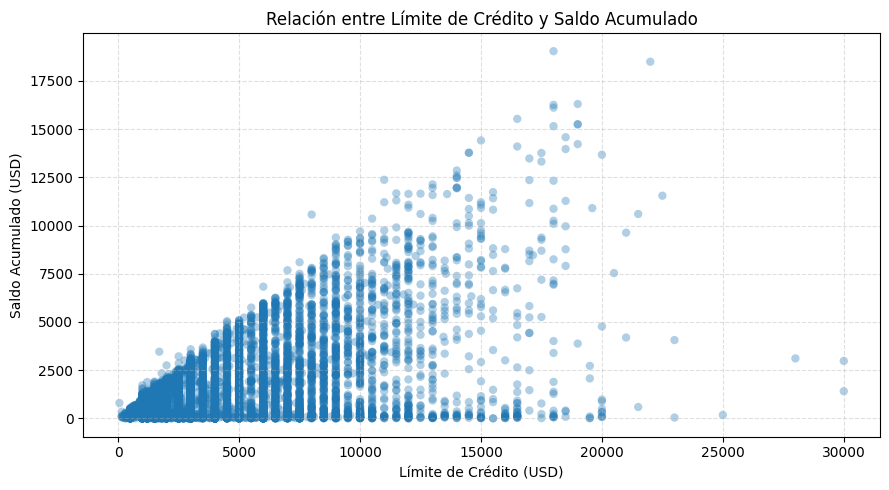

In [5]:
plt.figure(figsize=(9, 5))
plt.scatter(ndf['credit_limit'], ndf['balance'], alpha=0.35, color='#1f77b4', edgecolors='none')
plt.title('Relación entre Límite de Crédito y Saldo Acumulado')
plt.xlabel('Límite de Crédito (USD)')
plt.ylabel('Saldo Acumulado (USD)')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

<details><summary>Insight</summary>

1. Existe una correlación positiva moderada ($r = 0.53$) entre el límite de crédito y el saldo pendiente; ninguna de las dos variables sigue una distribución normal ($p < 0.05$) debido a su fuerte sesgo a la derecha (`credit_limit` con media de $\$4,494$ vs. mediana de $\$3,000$; `balance` con media de $\$1,564$ vs. mediana de $\$873$).

2. Se detectaron 695 outliers ($7.8\%$) en saldo pendiente (hasta $\$19,043$) y 248 outliers ($2.8\%$) en límite de crédito (hasta $\$30,000$), mostrando un grupo reducido de clientes con deudas y líneas muy superiores al promedio.

</details>

[Volver al inicio](#scrollTo=Z6M2eryOpIT7)

## 4. Pregunta de Investigación 2

**¿Qué diferencias existen en la distribución, dispersión y presencia de outliers entre el gasto en compras (`purchases`) y los adelantos de efectivo (`cash_advance`) según el nivel de crédito del cliente?**

In [6]:
for col in ['purchases', 'cash_advance']:
    media = ndf[col].mean()
    mediana = ndf[col].median()
    moda = ndf[col].mode()[0]
    std = ndf[col].std()
    iqr = ndf[col].quantile(0.75) - ndf[col].quantile(0.25)
    stat_ks, p_val = stats.kstest(ndf[col], 'norm', args=(media, std))
    q1 = ndf[col].quantile(0.25)
    q3 = ndf[col].quantile(0.75)
    outliers = ndf[(ndf[col] < q1 - 1.5 * iqr) | (ndf[col] > q3 + 1.5 * iqr)]

    print(f"=== {col.upper()} ===")
    print(f"Media: {media:.2f} | Mediana: {mediana:.2f} | Moda: {moda:.2f}")
    print(f"Desviación Estándar: {std:.2f} | IQR: {iqr:.2f}")
    print(f"Normalidad KS p-valor: {p_val:.4e}")
    print(f"Outliers (IQR): {len(outliers)} ({len(outliers)/len(ndf)*100:.1f}%)\n")

def credit_cls(x):
    if x <= 2000:
        return '<= 2,000'
    elif x <= 5000:
        return '2,001 - 5,000'
    elif x <= 10000:
        return '5,001 - 10,000'
    return '> 10,000'

ndf['credit_gp'] = ndf['credit_limit'].apply(credit_cls)
pivot_q2 = pd.pivot_table(ndf, index='credit_gp', values=['purchases', 'cash_advance'], aggfunc='median')
pivot_q2

=== PURCHASES ===
Media: 1003.32 | Mediana: 361.49 | Moda: 0.00
Desviación Estándar: 2136.73 | IQR: 1070.37
Normalidad KS p-valor: 0.0000e+00
Outliers (IQR): 808 (9.0%)

=== CASH_ADVANCE ===
Media: 978.96 | Mediana: 0.00 | Moda: 0.00
Desviación Estándar: 2097.26 | IQR: 1113.87
Normalidad KS p-valor: 0.0000e+00
Outliers (IQR): 1030 (11.5%)



,cash_advance,purchases
credit_gp,,
"2,001 - 5,000",0.000000,353.22
"5,001 - 10,000",36.336457,685.15
"<= 2,000",0.000000,222.89
"> 10,000",103.102091,1134.38


In [7]:
fig = px.box(
    ndf.melt(value_vars=['purchases', 'cash_advance'], var_name='Tipo_Operacion', value_name='Monto_USD'),
    x='Monto_USD',
    y='Tipo_Operacion',
    color='Tipo_Operacion',
    title='Distribución y Outliers: Compras vs. Adelantos de Efectivo',
    labels={'Monto_USD': 'Monto (USD)', 'Tipo_Operacion': 'Tipo de Operación'},
    width=850,
    height=420
)
fig.show()

<details><summary>Insight</summary>

1. Más del $50\%$ de los clientes nunca realiza adelantos de efectivo (mediana y moda iguales a $\$0.00$), mientras que en compras la mediana alcanza los $\$361.28$; además, conforme aumenta el límite de crédito, la mediana de compras crece de $\$249$ hasta $\$1,341$ USD.

2. Ambas variables rechazan la prueba de normalidad ($p < 0.05$) y presentan alta dispersión ($std > \$2,090$ USD), con 1,030 outliers ($11.5\%$) en adelantos de efectivo y 808 outliers ($9.0\%$) en compras, evidenciando un segmento minoritario con movimientos financieros extremos.

</details>

[Volver al inicio](#scrollTo=Z6M2eryOpIT7)